In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from lens.raytrace import trace, best_spot, spot_at
from lens.design import R2_for

R1, t = 29.5, 6.0
R2 = R2_for(R1, t, 50)
design = [(0, R1, 1.5), (t, R2, 1.0)]
rays = np.linspace(-10, 10, 1001)
print(best_spot(design))

(np.float64(51.3), np.float64(0.06836939187099818))


In [2]:
angle = np.radians(5)
z_last, y, u = trace(rays, design, angle)
y_sensor = y + np.tan(u) * (51.3 - z_last)

print(angle)
print(y_sensor.mean(), 50 * np.tan(angle))
print(y_sensor.min(), y_sensor.max())

0.08726646259971647
4.268121518787996 4.3744331762962
3.9583457576353 4.607680540366296


the image lands around 4.27 mm above the axis, close to f tan θ = 4.37. 

the rays spread from 3.96 to 4.61 mm.

In [3]:
print(np.sqrt(np.mean(y_sensor ** 2))) # from y = 0
print(np.std(y_sensor))  

4.269396687979102
0.10433973445320961


when measured from y = 0, it says 4.27 mm of blur, which is wrong: that’s just where the image is. 

the real blur is 0.104 mm.

In [4]:
for deg in [0, 5, 10]:
    z_last, y, u = trace(rays, design, np.radians(deg))
    y_sensor = y + np.tan(u) * (51.3 - z_last)
    print(deg, y_sensor.mean(), np.std(y_sensor))

0 1.0647493542858644e-17 0.06836939187099818
5 4.268121518787996 0.10433973445320961
10 8.597469095805755 0.32836708272680826


the center of the image is sharp (0.068), but at 10° the spot is 0.328 mm, about 5 times blurrier. 

the 10° rays meet nicely BEFORE the actual sensor, but at the sensor the spot is pretty big.

In [5]:
for deg in [0, 5, 10, 15]:
    z_last, y, u = trace(rays, design, np.radians(deg))
    y_sensor = y + np.tan(u) * (51.3 - z_last)
    print(deg, np.std(y_sensor))

0 0.06836939187099818
5 0.10433973445320961
10 0.32836708272680826
15 0.7549174280462263


In [6]:
plano_convex_lens = [(0, 25, 1.5), (5, np.inf, 1.0)]
sensor_pcl, spot_pcl = best_spot(plano_convex_lens)
for deg in [0, 5, 10, 15]:
    z_last_pcl, y, u = trace(rays, plano_convex_lens, np.radians(deg))
    y_sensor_pcl = y + np.tan(u) * (sensor_pcl - z_last_pcl)
    print(deg, np.std(y_sensor_pcl))

0 0.0765243470547916
5 0.11621002000790093
10 0.348462358201793
15 0.7928039372813959


the best-form lens is sharper at every angle, but both get about 11x blurrier from the center to 15°.

the edge blur is a much bigger problem than the choice between these two shapes.

In [8]:
for deg in [0, 5, 10, 15]:
    sensor_bfl, spot_bfl = best_spot(design, np.radians(deg))
    print(deg, sensor_bfl, spot_bfl)


0 51.3 0.06836939187099818
5 50.65 0.06954211800077396
10 48.8 0.0738900334729725
15 45.8 0.08443340880992492


at their own best positions all angles are sharp (0.068 → 0.084 mm). but the best position moves closer to the lens as the angle grows: 51.3 mm at 0°, 45.8 mm at 15°.

the sensor is flat and fixed at 51.3, so the edge rays meet before it and spread out again by the time they land.

this effect is called "field curvature".

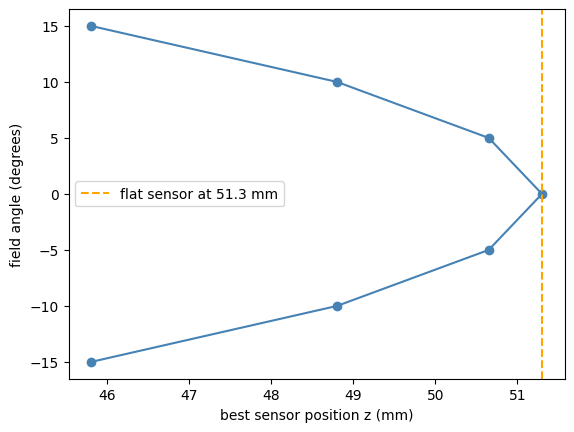

In [15]:
angles = [-15, -10, -5, 0, 5, 10, 15]
positions = []
for deg in angles:
    z_best, s = best_spot(design, np.radians(deg))
    positions.append(z_best)
plt.plot(positions, angles, "o-", color = "steelblue")
plt.axvline(51.3, ls = "--", color = "orange", label = "flat sensor at 51.3 mm")
plt.xlabel("best sensor position z (mm)")
plt.ylabel("field angle (degrees)")
plt.legend()
plt.show()

the sharp image lies on a curve that bends toward the lens on both sides: a bowl shape (field curvature). the flat sensor only touches it at the center, which is why the edges blur.

refocusing, unfortunately cannot fix this problem because, if we were to move the sensor closer to, say, the ebst position of a (10, -10) degree angle rays, then the flat rays will get affected. we cannot address the problems of edge rays without affecting the center part of the image (flat rays) at the same time. they both co-exist. so refocusing cannot be the fix!